In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from numpy.linalg import inv
from numpy.linalg import pinv
import cv2
import itertools as it
import os

In [2]:
# datasets
file_train_spec_data = '24_color_spectrum.txt'
file_train_color_data = '24_color_sRGB.txt'

train_spec = np.loadtxt(file_train_spec_data).T
print('train_spec shape', train_spec.shape)

train_color = np.loadtxt(file_train_color_data)
train_color = train_color / 255
print('train_color shape', train_color.shape)

train_spec shape (24, 401)
train_color shape (3, 24)


In [3]:
def adjC(c):

    cond1 = abs(c) > 0.04045
    cond2 = abs(c) <= 0.04045

    c[cond1] = pow((c[cond1] + 0.055)/1.055, 2.4)
    c[cond2] = c[cond2]/12.92

    return c

In [4]:
m = np.array([[0.4124564,0.3575761,0.1804375], [0.2126729,0.7151522,0.0721750], [0.0193339,0.1191920,0.9503041]])

In [5]:
xyz_c = m.dot(adjC(train_color.reshape(-1)).reshape(-1,24)) * 100
xyz_c= xyz_c.T
print('xyz_c shape', xyz_c.shape)

xyz_c shape (24, 3)


In [6]:
xyz_c

array([[11.13131632, 10.09748163,  6.83043318],
       [37.18466368, 34.89564939, 25.89167335],
       [18.08045629, 18.94917604, 34.5966273 ],
       [10.30598958, 13.15644627,  7.30558065],
       [25.32590858, 23.59879206, 44.80716371],
       [31.04384986, 42.1785876 , 44.52780359],
       [35.65016961, 29.40354146,  6.18039705],
       [13.93010449, 11.93994955, 37.63960821],
       [27.90259808, 19.55372456, 14.10678791],
       [ 8.93831225,  6.69433553, 15.00573275],
       [32.81364022, 43.50462938, 11.51803068],
       [44.33396249, 42.24255098,  8.40291052],
       [ 8.80285659,  6.37955111, 29.61573829],
       [14.31751128, 22.9618039 ,  9.97963405],
       [19.81602105, 12.0813737 ,  5.56258219],
       [53.62879973, 57.93776228,  9.65444288],
       [29.24682261, 19.39272515, 30.63075368],
       [14.91791666, 19.3978961 , 36.66920181],
       [85.03711584, 89.56670535, 96.79534982],
       [54.89728812, 57.75804982, 62.8886911 ],
       [33.41211898, 35.15326347, 38.275

In [7]:
class ColorReproducer:
    
    def __init__(self): 
        self.light_spec = None
        self.cmf = None
        self.ma = None
        self.d65 = np.array([0.95047, 1.00000000, 1.08883])
        self.is_ignore_ca = False
        
        self.light_spec_x3 = None
        self.cal_fact = None
        self.k = None
        self.white_light_k = None
        
    def prepare(self):
        self.light_spec_x3 = np.array([self.light_spec,self.light_spec,self.light_spec]).T 
        self.cal_fact = self.cmf * self.light_spec_x3
        self.k = 100.0 / sum(self.cal_fact[:,1])
        self.white_light_k = np.dot(self.cmf.T, self.light_spec) * (self.k / 100.0)
        self.cal_fact = self.cal_fact * self.k
 
        return

    def load(self, setup_path):
        self.light_spec = np.loadtxt(os.path.join(setup_path, 'CR_light.txt'))
        self.cmf = np.loadtxt(os.path.join(setup_path, 'CR_cmf.txt'))
        self.ma = np.loadtxt(os.path.join(setup_path, 'CR_ma.txt'))
        
        self.prepare()
        return
    
#     function adj(C) {
#   if (Abs(C) < 0.0031308) {
#     return 12.92 * C;
#   }
#   return 1.055 * Math.pow(C, 0.41666) - 0.055;
# }
    
    def adjC(self, c):
        
        cond1 = abs(c) < 0.0031308
        cond2 = abs(c) >= 0.0031308
        
        c[cond1] = 12.92 * c[cond1]
        c[cond2] = 1.055 * pow(c[cond2], 0.41666) - 0.055

        return c
        
    def reproduce(self, img_spec, gain = 1.0, is_normalize = False, filter_band = None):
        
        dims = len(img_spec.shape)
        
        if dims == 2:
            hw,c = img_spec.shape
        elif dims == 3:
            h,w,c = img_spec.shape
        
        img_spec = img_spec.reshape((-1,c));
        
        fact = None
        
        if self.is_ignore_ca:
            fact = self.cal_fact
        else:
            fact = inv(self.ma).dot(np.diag(self.ma.dot(self.d65) / self.ma.dot(self.white_light_k))).dot(self.ma)
            fact = fact.dot(self.cal_fact.T).T 
            
        op_ref_spec = None
        
        if filter_band is not None:

            filter_band_set = filter_band - 380

            mask = np.zeros((w*h, 401))
            
            mask[:,filter_band_set] = 1

            op_ref_spec = img_spec * mask * gain

        else:

            op_ref_spec = img_spec * gain
        
        
        if is_normalize: 
            
            img_rep_xyz = op_ref_spec.dot(fact)

            min_v = img_rep_xyz.min()
            max_v = img_rep_xyz.max()

            img_rep_xyz = (img_rep_xyz - min_v) / (max_v - min_v)
            
        else:
            
            img_rep_xyz = op_ref_spec.dot(fact)
        
#         print('min', np.min(img_rep_xyz))
#         print('max', np.max(img_rep_xyz))
        
        img_rep_xyz.reshape(-1, 3)
            
        return img_rep_xyz

In [8]:

reproducer = ColorReproducer()
reproducer.load('cr_weights')

In [9]:
light_d65 = np.loadtxt(r'lights\D65.txt').T

In [10]:
reproducer.light_spec = light_d65
# reproducer.light_spec = light_wli
reproducer.prepare()

In [11]:
xyz_s = reproducer.reproduce(train_spec, 1.0, False, None)

In [12]:
xyz_s

array([[10.97212561,  9.70385835,  6.05719972],
       [38.13697502, 35.58906751, 25.94288525],
       [17.85716939, 19.08240463, 34.53624778],
       [10.10906897, 12.97881838,  6.69536119],
       [25.83635456, 24.39024351, 45.32365982],
       [31.28652596, 42.72380817, 44.72201733],
       [36.45979099, 29.32987903,  5.90850855],
       [13.41444457, 11.76395347, 37.21378034],
       [28.46119523, 19.23980405, 13.75105866],
       [ 8.68523951,  6.52662313, 14.69304509],
       [33.2017832 , 43.64096275, 11.21048116],
       [46.17994894, 43.12414978,  8.4306821 ],
       [ 8.40577674,  6.23581278, 29.96969019],
       [14.5047174 , 23.55655972,  9.53031238],
       [20.18873961, 11.8390044 ,  5.1981556 ],
       [56.04861782, 59.62537859,  9.57486205],
       [29.42926758, 19.28664194, 30.28080352],
       [14.48154847, 19.87154549, 39.52637441],
       [84.13653499, 88.72447581, 95.41527081],
       [55.54763494, 58.38566185, 63.41229982],
       [34.05549779, 35.81726432, 39.054

In [13]:
def get_extend_color(src_rgb):

    extend = np.array([np.ones(src_rgb[:,0].shape), src_rgb[:,0], src_rgb[:,1], src_rgb[:,2], np.power(src_rgb[:,0],2), np.power(src_rgb[:,1],2), np.power(src_rgb[:,2],2),src_rgb[:,0]* src_rgb[:,1],src_rgb[:,0]* src_rgb[:,2],src_rgb[:,1]* src_rgb[:,2],src_rgb[:,0]*src_rgb[:,1]* src_rgb[:,2], np.power(src_rgb[:,0],3), np.power(src_rgb[:,1],3), np.power(src_rgb[:,2],3)])

    return extend

In [14]:
exp_c = get_extend_color(xyz_c)

In [25]:
c = np.dot(xyz_s.T, pinv(exp_c))

In [17]:
xyz_adj = np.dot(c, exp_c)

In [31]:
from sklearn.metrics import mean_squared_error
rmse = mean_squared_error(xyz_adj.reshape(-1,1), xyz_s.T.reshape(-1,1), squared=True)
rmse

0.1169640512479629

In [32]:
from sklearn.metrics import mean_squared_error
rmse = mean_squared_error(xyz_c.reshape(-1,1), xyz_s.T.reshape(-1,1), squared=True)
rmse

963.9464036079311

In [36]:
np.savetxt('xyz_adj.txt', xyz_adj.T, delimiter='\t')
np.savetxt('xyz_s.txt', xyz_s, delimiter='\t')

(3, 24)

In [40]:
def adjC(c):

    cond1 = abs(c) < 0.0031308
    cond2 = abs(c) >= 0.0031308

    c[cond1] = 12.92 * c[cond1]
    c[cond2] = 1.055 * pow(c[cond2], 0.41666) - 0.055

    return c
        
def xyz2rgb(xyz):
#     img_rep_xyz.reshape(-1, 3)
    m = np.array([[3.2404542, -1.5371385, -0.4985314], [-0.9692660,  1.8760108,  0.0415560], [ 0.0556434, -0.2040259,  1.0572252]])
    m = m.T

    img_rep_rgb = np.dot(xyz/100, m)

    img_rep_rgb[img_rep_rgb<0] = 0
    img_rep_rgb[img_rep_rgb>1] = 1

    img_rep_rgb = adjC(img_rep_rgb)

    img_rep_rgb = img_rep_rgb * 255.0

    img_rep_rgb[img_rep_rgb<0] = 0
    img_rep_rgb[img_rep_rgb>255] = 255
    img_rep_rgb = img_rep_rgb.astype('uint8')
    
    return img_rep_rgb

In [41]:
xyz_adj.shape

(3, 24)

In [57]:
from colormath.color_conversions import convert_color
from colormath.color_objects import LabColor, XYZColor
from colormath.color_diff import delta_e_cie2000
from skimage.color import rgb2lab, lab2rgb

In [58]:
def cal_delta_e_cie2000_lab(lab_src, lab_test):
    
    errs = np.zeros(lab_src.shape[0])
    
    for i in range(lab_src.shape[0]):
        
        color0 = LabColor(lab_l=lab_src[i,0], lab_a=lab_src[i,1], lab_b=lab_src[i,2])
        color1 = LabColor(lab_l=lab_test[i,0], lab_a=lab_test[i,1], lab_b=lab_test[i,2])

        errs[i] = delta_e_cie2000(color0, color1)
        
    return errs

def cal_delta_e_cie2000_rgb(rgb_src, rgb_test):
    
    lab_src = rgb2lab(rgb_src)
    lab_test = rgb2lab(rgb_test)
    
    errs = np.zeros(lab_src.shape[0])
    
    for i in range(lab_src.shape[0]):
        
        color0 = LabColor(lab_l=lab_src[i,0], lab_a=lab_src[i,1], lab_b=lab_src[i,2])
        color1 = LabColor(lab_l=lab_test[i,0], lab_a=lab_test[i,1], lab_b=lab_test[i,2])

        errs[i] = delta_e_cie2000(color0, color1)
    
    # ignore gray
#     return errs[:-6]

    return errs

def rmse(errs):
    return np.sqrt(((errs) ** 2).mean())

In [59]:
def plot_diff(rgb1, rgb2):
    
    rgb1 = rgb1.astype('uint8')
    rgb2 = rgb2.astype('uint8')
    
    errs = cal_delta_e_cie2000_rgb(rgb1, rgb2)
    
    plt.figure(figsize=(4, 14))
    plt.axis('off')
    plt.xlim(0, 30)
    plt.ylim(-2, 26)

    plt.annotate('c1.', (8, 25), fontsize = 20)
    plt.annotate('c2.', (16, 25), fontsize = 20)
    plt.annotate('CIEDE2000', (24, 25), fontsize = 20)

    plt.annotate('mean', (16, -1), fontsize = 20)
    plt.annotate('%.2f' %(np.mean(errs)), (26, -1), fontsize = 20)

    plt.annotate('rmse', (16, -2), fontsize = 20)
    plt.annotate('%.2f' %(rmse(errs)), (26, -2), fontsize = 20)
    
    for i in range(24):

        now_c1 = rgb1[i,:]
        now_c2 = rgb2[i,:]

        plt.scatter([10], [24 - i], marker='s', s = 500, color = (now_c1[0]/255, now_c1[1]/255, now_c1[2]/255))
        plt.scatter([18], [24 - i], marker='s', s = 500, color = (now_c2[0]/255, now_c2[1]/255, now_c2[2]/255))

        plt.annotate('%.2f' %(errs[i]), (26, 24 - i - 0.2), fontsize = 20)

    plt.show()

In [149]:
rgb_adj = xyz2rgb(xyz_adj.T)
rgb_c = xyz2rgb(xyz_c)
rgb_s = xyz2rgb(xyz_s)

In [147]:
rgb_c = train_color.T*255
rgb_c = rgb_c.astype('uint8')

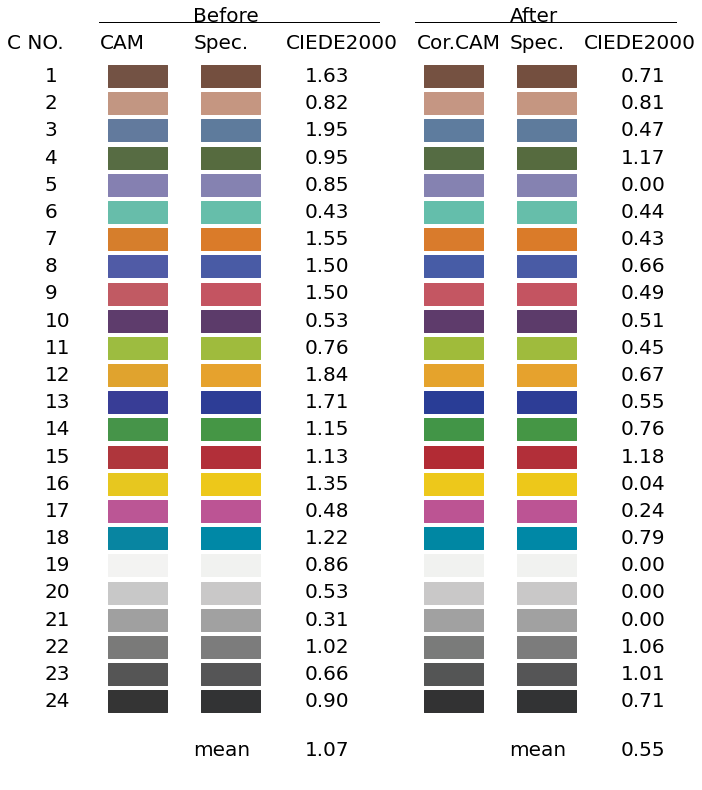

In [150]:
errs1 = cal_delta_e_cie2000_rgb(rgb_c, rgb_s)
errs2 = cal_delta_e_cie2000_rgb(rgb_adj, rgb_s)

plt.figure(figsize=(12, 14))
plt.axis('off')
plt.xlim(0, 36)
plt.ylim(-2, 26)

plt.annotate('Before', (10, 26), fontsize = 20)
plt.plot([5,20], [26,26], 'k', lw=2)

plt.annotate('C NO.', (0, 25), fontsize = 20)
plt.annotate('CAM', (5, 25), fontsize = 20)
plt.annotate('Spec.', (10, 25), fontsize = 20)
plt.annotate('CIEDE2000', (15, 25), fontsize = 20)

plt.annotate('mean', (10, -1), fontsize = 20)
plt.annotate('%.2f' %(np.mean(errs1)), (16, -1), fontsize = 20)

# plt.annotate('rmse', (10, -2), fontsize = 20)
# plt.annotate('%.2f' %(rmse(errs1)), (16, -2), fontsize = 20)

for i in range(24):

    now_c1 = rgb_c[i,:]
    now_c2 = rgb_s[i,:]
    
    plt.annotate('%d' %(i+1), (2, 24 - i - 0.2), fontsize = 20)

    plt.scatter([6], [24 - i], marker='s', s = 500, color = (now_c1[0]/255, now_c1[1]/255, now_c1[2]/255))
    plt.scatter([7], [24 - i], marker='s', s = 500, color = (now_c1[0]/255, now_c1[1]/255, now_c1[2]/255))
    plt.scatter([8], [24 - i], marker='s', s = 500, color = (now_c1[0]/255, now_c1[1]/255, now_c1[2]/255))
    plt.scatter([11], [24 - i], marker='s', s = 500, color = (now_c2[0]/255, now_c2[1]/255, now_c2[2]/255))
    plt.scatter([12], [24 - i], marker='s', s = 500, color = (now_c2[0]/255, now_c2[1]/255, now_c2[2]/255))
    plt.scatter([13], [24 - i], marker='s', s = 500, color = (now_c2[0]/255, now_c2[1]/255, now_c2[2]/255))
    
    plt.annotate('%.2f' %(errs1[i]), (16, 24 - i - 0.2), fontsize = 20)
    
    
     
plt.annotate('After', (27, 26), fontsize = 20)
plt.plot([22,36], [26,26], 'k', lw=2)

plt.annotate('Cor.CAM', (22, 25), fontsize = 20)
plt.annotate('Spec.', (27, 25), fontsize = 20)
plt.annotate('CIEDE2000', (31, 25), fontsize = 20)

plt.annotate('mean', (27, -1), fontsize = 20)
plt.annotate('%.2f' %(np.mean(errs2)), (33, -1), fontsize = 20)

# plt.annotate('rmse', (27, -2), fontsize = 20)
# plt.annotate('%.2f' %(rmse(errs2)), (33, -2), fontsize = 20)

for i in range(24):

    now_c1 = rgb_adj[i,:]
    now_c2 = rgb_s[i,:]
    
    plt.scatter([6 + 17], [24 - i], marker='s', s = 500, color = (now_c1[0]/255, now_c1[1]/255, now_c1[2]/255))
    plt.scatter([7 + 17], [24 - i], marker='s', s = 500, color = (now_c1[0]/255, now_c1[1]/255, now_c1[2]/255))
    plt.scatter([8 + 17], [24 - i], marker='s', s = 500, color = (now_c1[0]/255, now_c1[1]/255, now_c1[2]/255))
    plt.scatter([11 + 17], [24 - i], marker='s', s = 500, color = (now_c2[0]/255, now_c2[1]/255, now_c2[2]/255))
    plt.scatter([12 + 17], [24 - i], marker='s', s = 500, color = (now_c2[0]/255, now_c2[1]/255, now_c2[2]/255))
    plt.scatter([13 + 17], [24 - i], marker='s', s = 500, color = (now_c2[0]/255, now_c2[1]/255, now_c2[2]/255))
    
    plt.annotate('%.2f' %(errs2[i]), (16 + 17, 24 - i - 0.2), fontsize = 20)
    
    
    


plt.show()

In [49]:
v1 = xyz[18:24, 1]
v2 = sim_color[18:24, 1]

In [80]:
v1

array([89.56670535, 57.75804982, 35.15326347, 19.43712894,  9.08417203,
        3.43398102])

In [81]:
v2

array([88.72447581, 58.38566185, 35.81726432, 20.30535196,  9.25886723,
        3.3549039 ])

In [82]:
aaa = np.array([[89.56670535, 57.75804982, 35.15326347, 19.43712894,  9.08417203, 3.43398102], [88.72447581, 58.38566185, 35.81726432, 20.30535196,  9.25886723, 3.3549039 ]])

In [69]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

In [86]:
model = LinearRegression()
model.fit(v1.reshape(-1,1), v2.reshape(-1,1))

LinearRegression()

In [90]:
p = model.predict(v1.reshape(-1,1))[:,0]

In [91]:
p

array([89.32239422, 57.7972972 , 35.39402139, 19.81798847,  9.55732306,
        3.95750073])

In [94]:
from sklearn.metrics import r2_score

r2 = r2_score(p, v2)

r2

0.9997036617551173

In [102]:
vx = np.linspace(3.43398102, 89.56670535, 100, endpoint=True)
vy = model.predict(vx.reshape(-1,1))[:,0]

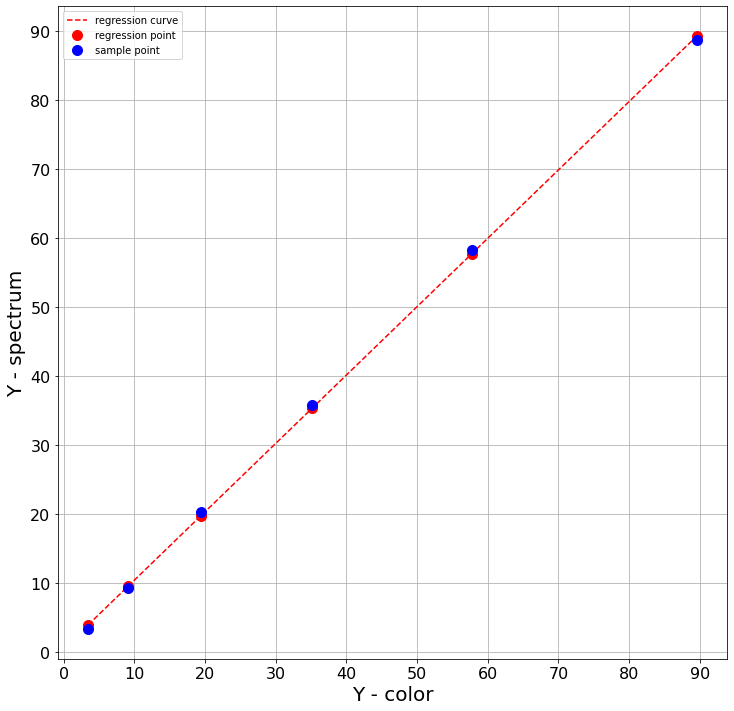

In [117]:
plt.figure(figsize=(12, 12))

# plt.title('Y- ')
plt.rc('xtick', labelsize=16) 
plt.rc('ytick', labelsize=16) 

plt.xticks(np.linspace(0, 90, 10))
plt.yticks(np.linspace(0, 90, 10))
plt.grid(True)

# plt.plot(v1, v2)
plt.plot(vx, vy, 'r--')

plt.plot(v1, p, 'ro', ms=10)
plt.plot(v1, v2, 'bo', ms=10)

plt.xlabel('Y - color', fontsize=20)
plt.ylabel('Y - spectrum', fontsize=20)

plt.legend(['regression curve', 'regression point', 'sample point'])

plt.show()